In [ ]:
# Import necessary libraries
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Load MNIST dataset (Handwritten digit images)
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

In [ ]:
# Normalize the data to the range [0,1] for better training stability
x_train, x_test = x_train / 255.0, x_test / 255.0


In [ ]:
# Flatten images for fully connected layers
x_train = x_train.reshape(-1, 28*28)
x_test = x_test.reshape(-1, 28*28)


In [ ]:
# Print dataset details
print(f"Training Samples: {x_train.shape[0]}, Test Samples: {x_test.shape[0]}")
print(f"Image Shape After Flattening: {x_train.shape[1]}")


Training Samples: 60000, Test Samples: 10000
Image Shape After Flattening: 784


In [ ]:
# Define Feedforward Neural Network (FNN)
model = keras.Sequential([
    keras.Input(shape=(28*28,)), # Input Layer
    layers.Dense(256, activation='relu'), # Hidden Layer 1
    layers.Dense(128, activation='relu'), # Hidden Layer 2
    layers.Dense(64, activation='relu'), # Hidden Layer 3
    layers.Dense(10, activation='softmax') # Output Layer for 10 digits (0-9)
])

In [ ]:
# Compile the model
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy',
metrics=['accuracy'])


In [ ]:
# Train the model
history = model.fit(x_train, y_train, epochs=10, validation_data=(x_test, y_test),
verbose=1)


Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 11ms/step - accuracy: 0.8867 - loss: 0.3789 - val_accuracy: 0.9628 - val_loss: 0.1170
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 18s 9ms/step - accuracy: 0.9702 - loss: 0.0940 - val_accuracy: 0.9678 - val_loss: 0.1012
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - accuracy: 0.9790 - loss: 0.0637 - val_accuracy: 0.9734 - val_loss: 0.0906
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 19s 10ms/step - accuracy: 0.9857 - loss: 0.0439 - val_accuracy: 0.9769 - val_loss: 0.0738
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 17s 9ms/step - accuracy: 0.9866 - loss: 0.0397 - val_accuracy: 0.9786 - val_loss: 0.0800
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.9900 - loss: 0.0303 - val_accuracy: 0.9755 - val_loss: 0.0859
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 22s 10ms/step - accuracy: 0.9911 - loss: 0.0260 - val_accuracy: 0.9713 - val_loss: 0.1204
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - accuracy: 0.9936 - los

In [ ]:
# Evaluate the model
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=2)
print(f"\nTest Accuracy: {test_acc:.4f}")

313/313 - 1s - 3ms/step - accuracy: 0.9807 - loss: 0.0867

Test Accuracy: 0.9807


In [ ]:
# Get predictions on test data
predictions = model.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [ ]:
# Function to display images with predictions
def display_predictions(images, labels, predictions, num_images=10):
  plt.figure(figsize=(12, 4))

  for i in range(num_images):
    plt.subplot(2, 5, i + 1) # Create a grid of 2 rows and 5 columns
    plt.imshow(images[i], cmap='gray')
    pred_label = np.argmax(predictions[i]) # Get the predicted label
    true_label = labels[i]
    color = 'green' if pred_label == true_label else 'red' # Green for correct, red for wrong
    plt.title(f"Pred: {pred_label}\nTrue: {true_label}", color=color)
    plt.axis('off')

  plt.tight_layout()
  plt.show()

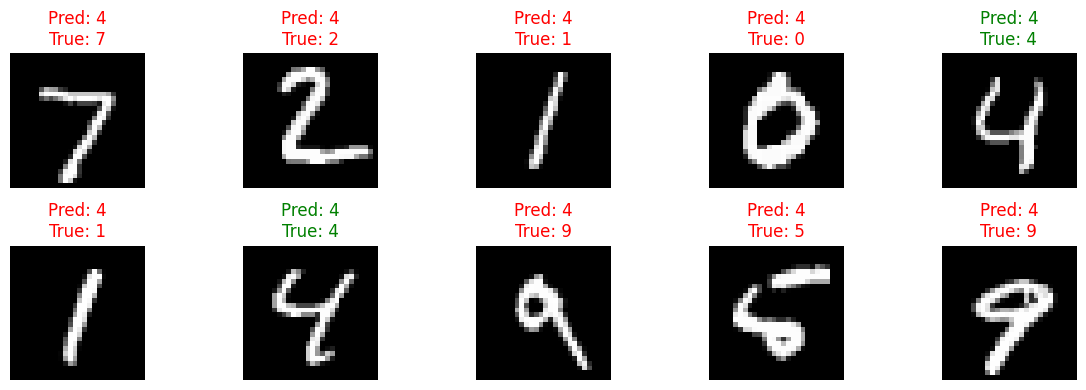

In [ ]:
# Display test images with predicted labels
x_test_images = x_test.reshape(-1, 28, 28) # Reshape back to 28x28 images
display_predictions(x_test_images, y_test, predictions, num_images=10)

LOSS ACCURACY:
for
1.
([
 layers.Dense(128, activation='relu', input_shape=(28*28,)), # Hidden Layer 1
 layers.Dense(64, activation='relu'), # Hidden Layer 2
 layers.Dense(10, activation='softmax') # Output Layer for 10 digits (0-9)
])
313/313 - 1s - 3ms/step - accuracy: 0.9766 - loss: 0.0842

Test Accuracy: 0.9766

2.
  keras.Input(shape=(28*28,)), # Input Layer
    layers.Dense(256, activation='relu'), # Hidden Layer 1
    layers.Dense(128, activation='relu'), # Hidden Layer 2
    layers.Dense(64, activation='relu'), # Hidden Layer 3
    layers.Dense(10, activation='softmax') # Output Layer for 10 digits (0-9)
])

313/313 - 1s - 3ms/step - accuracy: 0.9807 - loss: 0.0867

Test Accuracy: 0.9807



DO SAME FOR ADDING AND REDUCING THE HIDDDEN LAYERS AND
WITH TANH ACT FUNC
